# CAREMap · 05 Do the shortages cluster?

v2, step 2. The map *looks* like it has hot spots (west Texas, the Colorado mountains, Hawaii, parts of the South). This notebook tests that formally instead of trusting the eye:

1. Does each shortage, on its own, bunch together geographically? (Moran's I)
2. Do the two shortages bunch *with each other*: are childcare-short counties surrounded by housing-pressured ones more than chance would give? (bivariate Moran's I)
3. Where are the hot spots, and do the High counties sit inside them? (local Moran / LISA)

Neighbors are counties that share a border or corner ("queen" contiguity). Island counties with no neighbors (Hawaii, parts of Alaska and a few coastal islands) are left out of the tests but stay in the main ranking. Significance comes from 999 random reshuffles of the scores across the map.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from libpysal.weights import Queen
from esda.moran import Moran, Moran_BV, Moran_Local, Moran_Local_BV
from esda.join_counts import Join_Counts

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)

s = pd.read_csv(ROOT / "data/processed/county_scores_v1.csv", dtype={"GEOID": str})
s["high_if_zero"] = s["high_if_zero"].astype(str).eq("True")
shp = gpd.read_file(f"zip://{ROOT / 'data/raw/manual/cb_2024_us_county_5m.zip'}")[["GEOID", "geometry"]]
g = shp.merge(s[s["tier"] != "Not scored"], on="GEOID", how="inner").to_crs(5070).reset_index(drop=True)

w_all = Queen.from_dataframe(g, use_index=False)
keep = [i for i in range(len(g)) if w_all.cardinalities[i] > 0]
g = g.iloc[keep].reset_index(drop=True)
w = Queen.from_dataframe(g, use_index=False)
w.transform = "r"
print(f"Scored counties with at least one neighbor: {len(g):,}; islands dropped: {len(w_all.islands)}")
print(f"Average neighbors per county: {np.mean(list(w.cardinalities.values())):.1f}")

Scored counties with at least one neighbor: 3,026; islands dropped: 9
Average neighbors per county: 5.7


## 1. Does each shortage bunch together?

Moran's I runs from about -1 to 1. Near 0 means scores are scattered like a random shuffle; positive means high-scoring counties sit next to other high-scoring counties.

In [2]:
np.random.seed(0)
rows = []
for col, label in [("childcare_score", "Childcare shortage"), ("housing_score", "Housing pressure"),
                   ("combined_score", "Combined score")]:
    mi = Moran(g[col].values, w, permutations=999)
    rows.append({"measure": label, "Moran's I": round(mi.I, 3), "p (999 reshuffles)": mi.p_sim})
uni = pd.DataFrame(rows)
uni

,measure,Moran's I,p (999 reshuffles)
0,Childcare shortage,0.283,0.001
1,Housing pressure,0.527,0.001
2,Combined score,0.430,0.001


## 2. Do the two shortages bunch with each other?

The bivariate Moran's I asks whether a county's childcare score is related to the housing scores of its *neighbors*. It is shown both ways round. For comparison, the same-county correlation between the two scores is also shown; notebook 01 found it near zero.

In [3]:
np.random.seed(0)
bv1 = Moran_BV(g["childcare_score"].values, g["housing_score"].values, w, permutations=999)
bv2 = Moran_BV(g["housing_score"].values, g["childcare_score"].values, w, permutations=999)
same = g["childcare_score"].rank().corr(g["housing_score"].rank())
bv = pd.DataFrame([
    {"test": "Same county: childcare vs housing (rank correlation)", "value": round(same, 3), "p": np.nan},
    {"test": "Childcare here vs housing next door (bivariate I)", "value": round(bv1.I, 3), "p": bv1.p_sim},
    {"test": "Housing here vs childcare next door (bivariate I)", "value": round(bv2.I, 3), "p": bv2.p_sim},
])
by_group = []
for grp in ["Metro", "Nonmetro"]:
    sub = g[g["group"] == grp].reset_index(drop=True)
    ws = Queen.from_dataframe(sub, use_index=False)
    k = [i for i in range(len(sub)) if ws.cardinalities[i] > 0]
    sub = sub.iloc[k].reset_index(drop=True); ws = Queen.from_dataframe(sub, use_index=False); ws.transform = "r"
    b = Moran_BV(sub["childcare_score"].values, sub["housing_score"].values, ws, permutations=999)
    by_group.append({"test": f"{grp} only: childcare here vs housing next door", "value": round(b.I, 3), "p": b.p_sim})
pd.concat([bv, pd.DataFrame(by_group)], ignore_index=True)

,test,value,p
0,Same county: childcare vs housing (rank correl...,-0.138,NaN
1,Childcare here vs housing next door (bivariate I),-0.008,0.228
2,Housing here vs childcare next door (bivariate I),-0.006,0.298
3,Metro only: childcare here vs housing next door,-0.098,0.001
4,Nonmetro only: childcare here vs housing next ...,0.048,0.003


## 3. Are the High counties clustered?

A join-count test: how often two neighboring counties are *both* High, compared with 999 random placements of the same number of High counties. Shown for all High counties and for confirmed High only.

In [4]:
np.random.seed(0)
jc_rows = []
for label, flag in [("All High (106)", g["tier"] == "High"),
                    ("Confirmed High (63)", (g["tier"] == "High") & ~g["high_if_zero"])]:
    w_b = Queen.from_dataframe(g, use_index=False); w_b.transform = "b"
    jc = Join_Counts(flag.astype(int).values, w_b, permutations=999)
    jc_rows.append({"set": label, "counties in test": int(flag.sum()), "High-High neighbor pairs": int(jc.bb),
                    "expected if random": round(jc.mean_bb, 1), "p": jc.p_sim_bb})
pd.DataFrame(jc_rows)

,set,counties in test,High-High neighbor pairs,expected if random,p
0,All High (106),103,34,9.9,0.001
1,Confirmed High (63),61,19,3.5,0.001


## 4. Where are the hot spots?

Local Moran (LISA) labels each county:
- **Hot spot**: high combined score, surrounded by high scores
- **Cold spot**: low, surrounded by low
- **High outlier / low outlier**: differs from its neighbors

Only counties significant at p < 0.05 (999 reshuffles) get a label. With about 3,000 tests some labels will be chance, so the map shows *regions* more reliably than individual counties.

In [5]:
np.random.seed(0)
lisa = Moran_Local(g["combined_score"].values, w, permutations=999, seed=0)
lab = {1: "Hot spot", 2: "Low outlier", 3: "Cold spot", 4: "High outlier"}
g["lisa"] = np.where(lisa.p_sim < 0.05, pd.Series(lisa.q).map(lab), "Not significant")

blisa = Moran_Local_BV(g["childcare_score"].values, g["housing_score"].values, w, permutations=999, seed=0)
blab = {1: "Childcare short, housing-pressured neighbors", 2: "Childcare fine, housing-pressured neighbors",
        3: "Neither", 4: "Childcare short, calm-housing neighbors"}
g["bv_lisa"] = np.where(blisa.p_sim < 0.05, pd.Series(blisa.q).map(blab), "Not significant")

print(g["lisa"].value_counts().to_string(), "\n")
hi = g[g["tier"] == "High"]
print(f"High counties inside a combined-score hot spot: {(hi['lisa'] == 'Hot spot').sum()} of {len(hi)}")
print(f"  confirmed: {((hi['lisa'] == 'Hot spot') & ~hi['high_if_zero']).sum()} of {(~hi['high_if_zero']).sum()}; "
      f"unconfirmed: {((hi['lisa'] == 'Hot spot') & hi['high_if_zero']).sum()} of {hi['high_if_zero'].sum()}")
print("\nHot-spot counties by state (top 10):")
print(g[g["lisa"] == "Hot spot"]["USPS"].value_counts().head(10).to_string())

lisa
Not significant    2004
Cold spot           505
Hot spot            388
Low outlier          73
High outlier         56 

High counties inside a combined-score hot spot: 54 of 103
  confirmed: 38 of 61; unconfirmed: 16 of 42

Hot-spot counties by state (top 10):
USPS
TX    112
TN     41
CA     29
AL     23
VA     23
ID     21
LA     19
GA     13
NV     12
UT     12


In [6]:
# group hot-spot counties into connected regions
hot = g[g["lisa"] == "Hot spot"].reset_index()
if len(hot):
    wh = Queen.from_dataframe(hot, use_index=False)
    hot["region_id"] = wh.component_labels
    regions = (hot.groupby("region_id")
               .agg(counties=("GEOID", "size"), states=("USPS", lambda x: ", ".join(sorted(set(x)))),
                    high=("tier", lambda x: (x == "High").sum()), kids_under5=("kids_under5", "sum"),
                    examples=("county_name", lambda x: ", ".join(list(x)[:4])))
               .sort_values("counties", ascending=False))
    regions = regions[regions["counties"] >= 3]
    display(regions.head(12))
    g = g.merge(hot[["GEOID", "region_id"]], on="GEOID", how="left")

,counties,states,high,kids_under5,examples
region_id,,,,,
5,108,"LA, TX",24,955918,"Bandera County, Culberson County, Howard Count..."
6,77,"AZ, CA, ID, NV, UT",8,1551769,"Clark County, Kings County, Gila County, Madis..."
0,72,"AL, GA, KY, MS, NC, TN",8,383519,"Warren County, Clay County, Murray County, Ble..."
17,15,VA,1,41732,"Middlesex County, Mathews County, Stafford Cou..."
14,10,WA,3,106656,"Thurston County, Kitsap County, Mason County, ..."
15,9,"NC, VA",1,59389,"Suffolk city, Gates County, Portsmouth city, C..."
27,9,LA,1,84641,"St. Tammany Parish, Jefferson Parish, St. Char..."
9,8,"ID, MT",0,20915,"Liberty County, Flathead County, Shoshone Coun..."
24,8,"NC, SC, TN",2,59938,"Buncombe County, Greene County, Cocke County, ..."


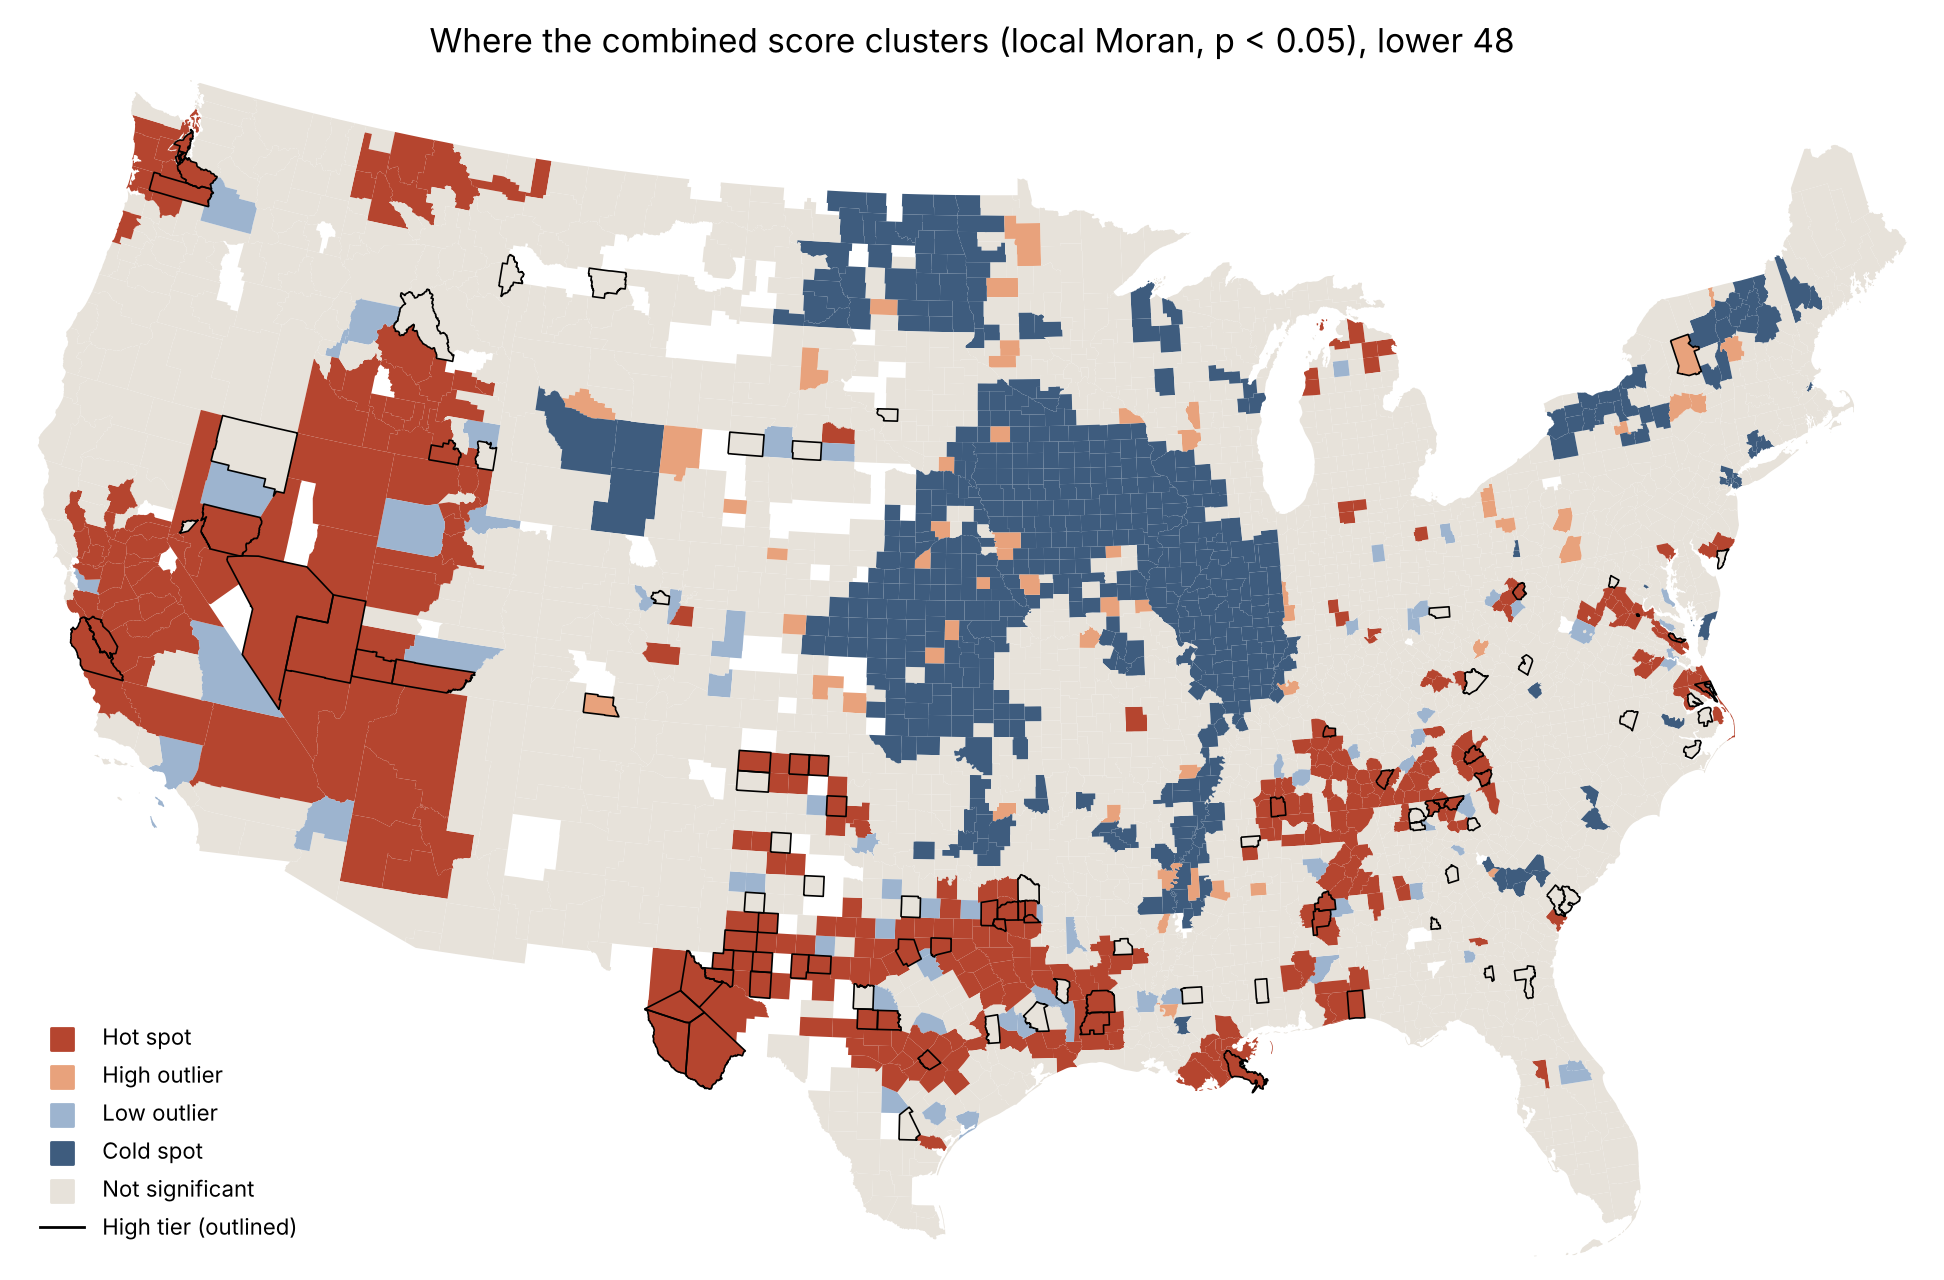

In [7]:
colors = {"Hot spot": "#B5452F", "High outlier": "#E8A27C", "Low outlier": "#9DB4CF",
          "Cold spot": "#3E5C7E", "Not significant": "#E7E2DA"}
fig, ax = plt.subplots(figsize=(11, 6.5))
g.plot(ax=ax, color=g["lisa"].map(colors), linewidth=0)
g[g["tier"] == "High"].boundary.plot(ax=ax, color="black", linewidth=0.6)
for k, c in colors.items():
    ax.scatter([], [], color=c, marker="s", s=60, label=k)
ax.plot([], [], color="black", lw=1, label="High tier (outlined)")
ax.legend(loc="lower left", fontsize=8, frameon=False)
ax.set_xlim(-2.4e6, 2.3e6); ax.set_ylim(2.6e5, 3.2e6); ax.set_axis_off()
ax.set_title("Where the combined score clusters (local Moran, p < 0.05), lower 48")
fig.tight_layout(); fig.savefig(FIG / "05_lisa_combined.png", dpi=150); plt.show()

In [8]:
out = g[["GEOID", "USPS", "county_name", "group", "tier", "high_if_zero", "lisa", "bv_lisa", "region_id"]].copy()
out["lisa_p"] = lisa.p_sim
out.to_csv(ROOT / "data/processed/county_clusters.csv", index=False)
pd.concat([uni.rename(columns={"measure": "test", "Moran's I": "value", "p (999 reshuffles)": "p"}), bv,
           pd.DataFrame(by_group), pd.DataFrame(jc_rows).rename(columns={"set": "test"})], ignore_index=True
          ).to_csv(ROOT / "data/processed/cluster_tests_summary.csv", index=False)
print("Saved county_clusters.csv and cluster_tests_summary.csv")

Saved county_clusters.csv and cluster_tests_summary.csv


## What this means

**Each shortage clusters on its own.** Childcare shortage (Moran's I 0.28) and housing pressure (0.53) both bunch together far more than a random shuffle would (p = 0.001). Housing pressure is the more regional of the two: high-cost regions spread across many neighboring counties.

**The two shortages do not travel together.** In the same county the two scores are slightly *opposed* (rank correlation -0.14). A county's childcare score is also unrelated to its neighbors' housing pressure (bivariate I about 0, p > 0.2). Split by type, there is a faint link in rural areas (0.05) and a faint opposite one in metros (-0.10). Both are statistically detectable but too small to matter. Housing-pressured regions are not, as a rule, childcare-short regions.

**But the places where they overlap are clustered.** High counties border each other 34 times, against about 10 expected by chance (confirmed High: 19 vs about 3.5). Half the High counties (54 of 103 tested) sit inside a hot spot of the combined score. The overlap happens where the two separately clustered patterns cross. That is mainly in three regions:
- Texas and western Louisiana: 108 counties, 24 of them High
- the Southwest and Great Basin (Arizona, Nevada, Utah, Idaho, inland California)
- the southern Appalachians (Tennessee, northern Alabama and Georgia)

Michigan has one small hot spot in the northeast Lower Peninsula (Cheboygan, Montmorency, Alpena, Charlevoix, Oscoda). Cheboygan was also the top licensed-slot candidate in notebook 04.

**Confirmed vs unconfirmed.** 38 of 61 confirmed High counties sit in a hot spot, against 16 of 42 unconfirmed ones. The unconfirmed counties are more often isolated, which fits their being driven by a single uncertain number.

**What it means for CAREMap.** There is no general rule that a housing-squeezed place is also a childcare-short place, so a combined program can't be targeted using one problem as a stand-in for the other. Both have to be measured, which is what the combined score does. The places where both problems hit come in regional clusters, so a program like Ouray's could work across several neighboring counties instead of one at a time. Archuleta County, Colorado is a "high outlier": High itself, but its neighbors are not, so it's a local case rather than part of a region. Maui and other island counties have no land neighbors and aren't part of this test.